<a href="https://colab.research.google.com/github/krishkumarwork3-beep/ucs420/blob/2nd/UCS420_Assignment10_Heart_Health_Assistant.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCS420 Cognitive Computing – Assignment 10
## Heart Health Information Assistant (Healthcare Cognitive Assistant)

> **Medical disclaimer:** This notebook is a university project for **educational purposes only**. It is **not a substitute for professional medical advice, diagnosis or treatment**. In a medical emergency in India, call **112** immediately.

**What this notebook builds:** a Python assistant that (1) understands a user's question about heart health, (2) identifies the intent with a TF-IDF + Logistic Regression classifier, (3) applies a rule engine (emergency escalation, low-confidence handling, unsupported-query refusal, etc.), (4) retrieves information from a knowledge base and (5) returns a structured response.

**Contents**
1. Labelled corpus  2. Hierarchical taxonomy  3. Domain concepts & relationships  4. NLP preprocessing  5. TF-IDF + classifier  6. Evaluation  7. Knowledge base  8. Rule engine  9. Integrated `assistant()`  10. Deployment (interactive interface)  – followed by an automatic **testing section**.

Run all cells top to bottom. The very last cell is an interactive `input()` loop (type `exit` to stop it).

## 0. Setup: imports, NLTK resources and random seeds
All libraries used here (pandas, numpy, nltk, scikit-learn, matplotlib, seaborn, networkx) are pre-installed in Google Colab. The required NLTK resources are downloaded inside this cell. No external dataset or file upload is needed – everything is defined inside the notebook.

In [1]:
import re, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import nltk
from IPython.display import display

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

warnings.filterwarnings("ignore")

# ---- Reproducibility ----
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# ---- Download the NLTK resources needed (quietly) ----
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    try:
        nltk.download(pkg, quiet=True)
    except Exception as e:
        print("Could not download", pkg, "->", e)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 200)

DISCLAIMER = ("This information is for educational purposes only and is not a substitute "
              "for professional medical advice, diagnosis or treatment.")
print("Setup complete.")
print("DISCLAIMER:", DISCLAIMER)

Setup complete.
DISCLAIMER: This information is for educational purposes only and is not a substitute for professional medical advice, diagnosis or treatment.


## 1. Labelled Corpus
A small hand-written corpus of **72 queries** (12 per intent) across **6 intent categories**: `symptoms`, `risk_factors`, `prevention_lifestyle`, `medication_info`, `diagnostic_tests` and `emergency`. The phrasing is deliberately varied (questions, statements, first-person descriptions) so that the classifier does not just memorise one sentence pattern. The data is stored in a pandas DataFrame with the columns `query` and `intent`, and the class distribution is shown below.

Total queries: 72


,query,intent
0,What causes heart palpitations?,symptoms
1,When should I call an ambulance for chest pain?,emergency
2,Does high cholesterol raise my risk of coronary artery disease?,risk_factors
3,What are the common symptoms of a heart attack?,symptoms
4,How can I prevent heart disease naturally?,prevention_lifestyle
5,What is an echocardiogram?,diagnostic_tests
6,How do heart attack symptoms differ in women?,symptoms
7,Can losing weight lower my cardiovascular risk?,prevention_lifestyle
8,What are the major risk factors for heart disease?,risk_factors
9,What is a troponin test?,diagnostic_tests



Class distribution:


,count
intent,
symptoms,12
emergency,12
risk_factors,12
prevention_lifestyle,12
diagnostic_tests,12
medication_info,12


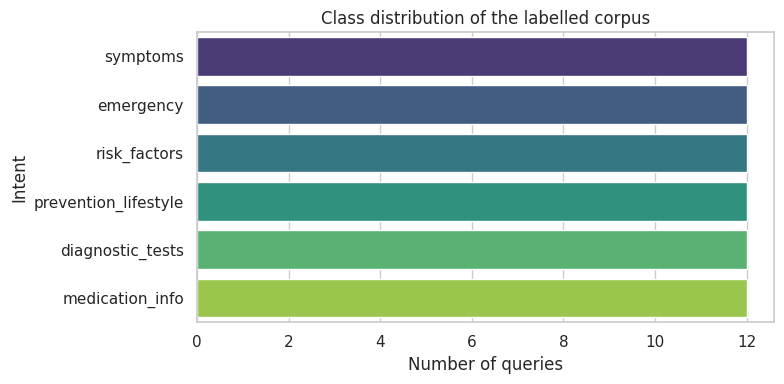

In [2]:
corpus = {
    "symptoms": [
        "What are the common symptoms of a heart attack?",
        "Why do I feel chest pain when I walk fast?",
        "What are the warning signs of heart disease?",
        "Is shortness of breath a sign of heart problems?",
        "What causes heart palpitations?",
        "Why does my heart race for no reason?",
        "Can swollen ankles be a symptom of heart failure?",
        "What does angina feel like?",
        "I feel dizzy and my heartbeat is irregular, what could it mean?",
        "Are fatigue and weakness symptoms of a weak heart?",
        "How do heart attack symptoms differ in women?",
        "What are the early signs of cardiac problems?",
    ],
    "risk_factors": [
        "What are the major risk factors for heart disease?",
        "Does high blood pressure increase the chance of a heart attack?",
        "Is smoking bad for my heart?",
        "Does family history affect my risk of heart disease?",
        "How does diabetes increase the risk of cardiovascular disease?",
        "Can obesity cause heart problems?",
        "Does high cholesterol raise my risk of coronary artery disease?",
        "Are men more likely than women to get heart disease?",
        "Does age make heart disease more likely?",
        "Can stress and poor sleep damage my heart?",
        "Why are Indians at higher risk of heart disease at a young age?",
        "Which habits put me at risk of a heart attack?",
    ],
    "prevention_lifestyle": [
        "How can I keep my heart healthy?",
        "What foods are good for heart health?",
        "How much exercise do I need to protect my heart?",
        "What diet helps lower cholesterol?",
        "How can I prevent heart disease naturally?",
        "Does quitting smoking improve heart health?",
        "How can I reduce my blood pressure with lifestyle changes?",
        "Is yoga or walking good for the heart?",
        "How much salt should I eat for a healthy heart?",
        "What lifestyle changes reduce the risk of a heart attack?",
        "Can losing weight lower my cardiovascular risk?",
        "What are some tips for a heart-healthy diet?",
    ],
    "medication_info": [
        "What do statins do for the heart?",
        "How do beta blockers work?",
        "Why do heart patients take aspirin?",
        "What are ACE inhibitors used for in hypertension?",
        "What are blood thinners and who needs them after a stent?",
        "What are the side effects of cholesterol lowering drugs?",
        "Which medicines are prescribed for high blood pressure?",
        "What is nitroglycerin used for in angina?",
        "Can I stop taking my heart medication when I feel better?",
        "How do anticoagulants help in arrhythmia?",
        "What medication is given after a heart attack?",
        "Which drugs are commonly used to treat heart failure?",
    ],
    "diagnostic_tests": [
        "What does an ECG test show?",
        "How is a heart attack diagnosed?",
        "What is an echocardiogram?",
        "Why would a doctor order a treadmill stress test for my heart?",
        "What is a coronary angiogram?",
        "Which blood tests check heart health?",
        "What is a troponin test?",
        "How is high blood pressure measured and diagnosed?",
        "What is a lipid profile for cholesterol?",
        "Do I need a CT scan of my heart arteries?",
        "What is a Holter monitor for heart rhythm?",
        "How do doctors find blockages in the heart?",
    ],
    "emergency": [
        "What should I do if someone is having a heart attack?",
        "How do I perform CPR on a person whose heart has stopped?",
        "When should I call an ambulance for chest pain?",
        "What is the first aid for a cardiac arrest?",
        "A person collapsed and has no pulse, what should I do?",
        "Which number should I call for a heart emergency in India?",
        "How do I use an AED on a person in cardiac arrest?",
        "Should I chew an aspirin during a suspected heart attack?",
        "What are the emergency steps when a person faints with chest pain?",
        "When is chest pain a medical emergency?",
        "How can I help a person whose heart and breathing have stopped?",
        "What immediate action should I take for a sudden heart emergency?",
    ],
}

rows = [(q, intent) for intent, qs in corpus.items() for q in qs]
df = pd.DataFrame(rows, columns=["query", "intent"])
df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)   # shuffle (seeded)

print("Total queries:", len(df))
display(df.head(10))

print("\nClass distribution:")
dist = df["intent"].value_counts()
display(dist.to_frame("count"))

plt.figure(figsize=(8, 4))
sns.countplot(data=df, y="intent", order=dist.index, palette="viridis")
plt.title("Class distribution of the labelled corpus")
plt.xlabel("Number of queries"); plt.ylabel("Intent")
plt.tight_layout(); plt.show()

## 2. Hierarchical Taxonomy
The domain is organised as a tree with **5 major categories**, each with **at least 2 subcategories**. Leaves list example topics. Every intent from Section 1 is then mapped to its place in this taxonomy (`Category > Subcategory`).

In [3]:
taxonomy = {
    "Symptoms": {
        "Warning Signs": ["chest pain / pressure", "shortness of breath", "unusual fatigue"],
        "Rhythm & Fluid Symptoms": ["palpitations", "dizziness", "swollen ankles"],
    },
    "Risk Factors": {
        "Modifiable": ["high blood pressure", "high cholesterol", "smoking", "diabetes", "obesity"],
        "Non-modifiable": ["age", "sex", "family history", "South Asian ancestry"],
    },
    "Prevention": {
        "Lifestyle": ["heart-healthy diet", "regular exercise", "salt reduction", "quitting tobacco"],
        "Routine Health Checks": ["blood pressure checks", "cholesterol screening", "blood sugar tests"],
    },
    "Diagnosis and Treatment": {
        "Diagnostic Tests": ["ECG", "echocardiogram", "stress test", "troponin", "angiography"],
        "Medications": ["statins", "beta blockers", "ACE inhibitors", "aspirin / blood thinners"],
        "Procedures": ["angioplasty and stent", "bypass surgery", "pacemaker"],
    },
    "Emergency Care": {
        "Recognition": ["when to call 112", "emergency warning signs"],
        "First Aid": ["CPR", "AED use", "aspirin during a heart attack"],
    },
}

def print_tree(node, prefix=""):
    """Print a nested dict / list as a tree."""
    if isinstance(node, dict):
        items = list(node.items())
        for i, (key, child) in enumerate(items):
            last = (i == len(items) - 1)
            print(prefix + ("└── " if last else "├── ") + key)
            print_tree(child, prefix + ("    " if last else "│   "))
    else:  # list of leaves
        for i, leaf in enumerate(node):
            last = (i == len(node) - 1)
            print(prefix + ("└── " if last else "├── ") + leaf)

print("HEART HEALTH TAXONOMY")
print_tree(taxonomy)

# Checks required by the assignment
assert len(taxonomy) >= 4 and all(len(sub) >= 2 for sub in taxonomy.values())
print("\nCategories:", len(taxonomy), "| Subcategories per category:",
      {k: len(v) for k, v in taxonomy.items()})

# Map each intent to its place in the taxonomy
INTENT_TO_TAXONOMY = {
    "symptoms":             ("Symptoms", "Warning Signs"),
    "risk_factors":         ("Risk Factors", "Modifiable"),
    "prevention_lifestyle": ("Prevention", "Lifestyle"),
    "medication_info":      ("Diagnosis and Treatment", "Medications"),
    "diagnostic_tests":     ("Diagnosis and Treatment", "Diagnostic Tests"),
    "emergency":            ("Emergency Care", "First Aid"),
}
for intent, (cat, sub) in INTENT_TO_TAXONOMY.items():
    assert cat in taxonomy and sub in taxonomy[cat]

map_df = pd.DataFrame([(i, c, s, f"{c} > {s}") for i, (c, s) in INTENT_TO_TAXONOMY.items()],
                      columns=["intent", "category", "subcategory", "taxonomy_path"])
print("\nIntent -> taxonomy mapping:")
display(map_df)

HEART HEALTH TAXONOMY
├── Symptoms
│   ├── Warning Signs
│   │   ├── chest pain / pressure
│   │   ├── shortness of breath
│   │   └── unusual fatigue
│   └── Rhythm & Fluid Symptoms
│       ├── palpitations
│       ├── dizziness
│       └── swollen ankles
├── Risk Factors
│   ├── Modifiable
│   │   ├── high blood pressure
│   │   ├── high cholesterol
│   │   ├── smoking
│   │   ├── diabetes
│   │   └── obesity
│   └── Non-modifiable
│       ├── age
│       ├── sex
│       ├── family history
│       └── South Asian ancestry
├── Prevention
│   ├── Lifestyle
│   │   ├── heart-healthy diet
│   │   ├── regular exercise
│   │   ├── salt reduction
│   │   └── quitting tobacco
│   └── Routine Health Checks
│       ├── blood pressure checks
│       ├── cholesterol screening
│       └── blood sugar tests
├── Diagnosis and Treatment
│   ├── Diagnostic Tests
│   │   ├── ECG
│   │   ├── echocardiogram
│   │   ├── stress test
│   │   ├── troponin
│   │   └── angiography
│   ├── Medications
│   │   

,intent,category,subcategory,taxonomy_path
0,symptoms,Symptoms,Warning Signs,Symptoms > Warning Signs
1,risk_factors,Risk Factors,Modifiable,Risk Factors > Modifiable
2,prevention_lifestyle,Prevention,Lifestyle,Prevention > Lifestyle
3,medication_info,Diagnosis and Treatment,Medications,Diagnosis and Treatment > Medications
4,diagnostic_tests,Diagnosis and Treatment,Diagnostic Tests,Diagnosis and Treatment > Diagnostic Tests
5,emergency,Emergency Care,First Aid,Emergency Care > First Aid


## 3. Domain Concepts and Relationships
The domain knowledge is modelled as a small **knowledge graph**: concepts (nodes) connected by typed relationships (edges), stored as `(subject, relation, object)` triples. There are **17 concepts** and **24 relationships**. The graph is drawn with `networkx` and `matplotlib`; nodes are coloured by concept type.

20 concepts, 24 relationships


,subject,relation,object
0,Hypertension,INCREASES_RISK_OF,Heart Attack
1,Hypertension,INCREASES_RISK_OF,Heart Failure
2,High Cholesterol,CAUSES,Atherosclerosis
3,Atherosclerosis,CAUSES,Angina
4,Atherosclerosis,INCREASES_RISK_OF,Heart Attack
5,Smoking,INCREASES_RISK_OF,Atherosclerosis
6,Diabetes,INCREASES_RISK_OF,Heart Attack
7,Obesity,INCREASES_RISK_OF,Hypertension
8,Heart Attack,CAUSES,Chest Pain
9,Heart Attack,MAY_LEAD_TO,Heart Failure


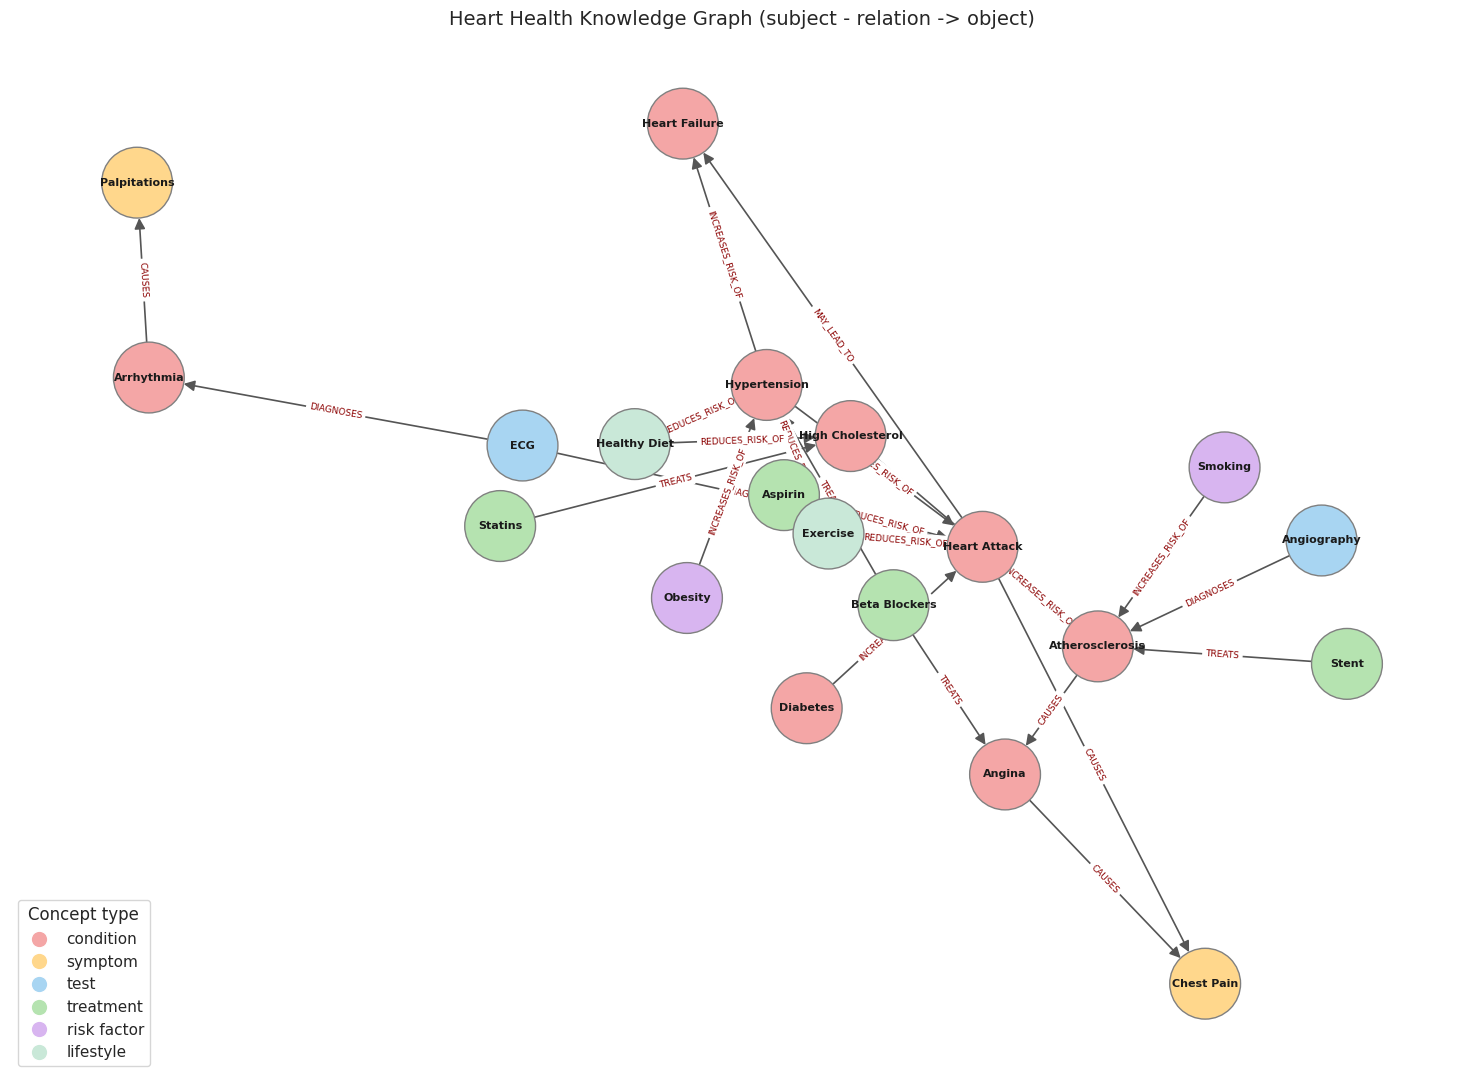

In [4]:
concept_types = {
    "Heart Attack": "condition", "Hypertension": "condition", "High Cholesterol": "condition",
    "Atherosclerosis": "condition", "Angina": "condition", "Arrhythmia": "condition",
    "Heart Failure": "condition", "Diabetes": "condition",
    "Chest Pain": "symptom", "Palpitations": "symptom",
    "ECG": "test", "Angiography": "test",
    "Statins": "treatment", "Beta Blockers": "treatment", "Aspirin": "treatment", "Stent": "treatment",
    "Smoking": "risk factor", "Obesity": "risk factor",
    "Exercise": "lifestyle", "Healthy Diet": "lifestyle",
}

triples = [
    ("Hypertension",     "INCREASES_RISK_OF", "Heart Attack"),
    ("Hypertension",     "INCREASES_RISK_OF", "Heart Failure"),
    ("High Cholesterol", "CAUSES",            "Atherosclerosis"),
    ("Atherosclerosis",  "CAUSES",            "Angina"),
    ("Atherosclerosis",  "INCREASES_RISK_OF", "Heart Attack"),
    ("Smoking",          "INCREASES_RISK_OF", "Atherosclerosis"),
    ("Diabetes",         "INCREASES_RISK_OF", "Heart Attack"),
    ("Obesity",          "INCREASES_RISK_OF", "Hypertension"),
    ("Heart Attack",     "CAUSES",            "Chest Pain"),
    ("Heart Attack",     "MAY_LEAD_TO",       "Heart Failure"),
    ("Angina",           "CAUSES",            "Chest Pain"),
    ("Arrhythmia",       "CAUSES",            "Palpitations"),
    ("ECG",              "DIAGNOSES",         "Arrhythmia"),
    ("ECG",              "DIAGNOSES",         "Heart Attack"),
    ("Angiography",      "DIAGNOSES",         "Atherosclerosis"),
    ("Statins",          "TREATS",            "High Cholesterol"),
    ("Beta Blockers",    "TREATS",            "Hypertension"),
    ("Beta Blockers",    "TREATS",            "Angina"),
    ("Aspirin",          "REDUCES_RISK_OF",   "Heart Attack"),
    ("Stent",            "TREATS",            "Atherosclerosis"),
    ("Exercise",         "REDUCES_RISK_OF",   "Heart Attack"),
    ("Exercise",         "REDUCES_RISK_OF",   "Hypertension"),
    ("Healthy Diet",     "REDUCES_RISK_OF",   "High Cholesterol"),
    ("Healthy Diet",     "REDUCES_RISK_OF",   "Hypertension"),
]

# every node in a triple must be a declared concept
assert all(s in concept_types and o in concept_types for s, _, o in triples)
concepts = sorted(set([s for s, _, _ in triples] + [o for _, _, o in triples]))
print(f"{len(concepts)} concepts, {len(triples)} relationships")
display(pd.DataFrame(triples, columns=["subject", "relation", "object"]))

# ---- Build and draw the graph ----
G = nx.DiGraph()
for c in concepts:
    G.add_node(c, ctype=concept_types[c])
for s, r, o in triples:
    G.add_edge(s, o, relation=r)

palette = {"condition": "#f4a6a6", "symptom": "#ffd78c", "test": "#a8d5f2",
           "treatment": "#b5e3b0", "risk factor": "#d8b5f0", "lifestyle": "#c9e8d8"}
node_colors = [palette[G.nodes[n]["ctype"]] for n in G.nodes]

plt.figure(figsize=(15, 11))
pos = nx.spring_layout(G, seed=SEED, k=1.6, iterations=200)
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=2600, edgecolors="grey")
nx.draw_networkx_labels(G, pos, font_size=8, font_weight="bold")
nx.draw_networkx_edges(G, pos, arrows=True, arrowstyle="-|>", arrowsize=16,
                       edge_color="#555555", node_size=2600, width=1.2)
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "relation"),
                             font_size=6.5, font_color="#8b0000", label_pos=0.5)
handles = [plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=c, markersize=12, label=t)
           for t, c in palette.items()]
plt.legend(handles=handles, loc="lower left", title="Concept type")
plt.title("Heart Health Knowledge Graph (subject - relation -> object)", fontsize=14)
plt.axis("off"); plt.tight_layout(); plt.show()

## 4. NLP Preprocessing
Each query goes through four steps using **NLTK**:
1. **Lowercase conversion**
2. **Tokenization** (`word_tokenize`; falls back to a regex tokenizer if the tokenizer data were unavailable)
3. **Stopword removal** (English stopwords; the words *not* and *no* are kept because negation can matter)
4. **Lemmatization** (`WordNetLemmatizer`, verb form first and then noun form, e.g. *diagnosed → diagnose*, *arteries → artery*)

The cell finishes with a before/after example.

In [5]:
STOP_WORDS = set(stopwords.words("english")) - {"not", "no"}
lemmatizer = WordNetLemmatizer()

def tokenize(text):
    """NLTK tokenization with a safe regex fallback."""
    try:
        return word_tokenize(text)
    except LookupError:
        return re.findall(r"[a-z']+", text)

def preprocess(text, as_tokens=False):
    """lowercase -> tokenize -> remove stopwords -> lemmatize."""
    text = str(text).lower().replace("’", "'")
    text = re.sub(r"\b(can't|cannot|can not)\b", "can not", text)   # keep the negation
    tokens = tokenize(text)
    tokens = [t for t in tokens if t.isalpha() and len(t) > 1]      # drop punctuation / fragments
    tokens = [t for t in tokens if t not in STOP_WORDS]
    tokens = [lemmatizer.lemmatize(lemmatizer.lemmatize(t, "v"), "n") for t in tokens]
    return tokens if as_tokens else " ".join(tokens)

# ---- Step-by-step before/after demo ----
example = "What are the Warning Signs of Heart Attacks in Women?"
step1 = example.lower()
step2 = tokenize(step1)
step3 = [t for t in step2 if t.isalpha() and t not in STOP_WORDS]
step4 = preprocess(example, as_tokens=True)
print("Original      :", example)
print("1. Lowercase  :", step1)
print("2. Tokens     :", step2)
print("3. No stopwords:", step3)
print("4. Lemmatized :", step4)
print("Final string  :", preprocess(example))

# Apply to the whole corpus
df["clean"] = df["query"].apply(preprocess)
display(df[["query", "clean"]].head(8))

Original      : What are the Warning Signs of Heart Attacks in Women?
1. Lowercase  : what are the warning signs of heart attacks in women?
2. Tokens     : ['what', 'are', 'the', 'warning', 'signs', 'of', 'heart', 'attacks', 'in', 'women', '?']
3. No stopwords: ['warning', 'signs', 'heart', 'attacks', 'women']
4. Lemmatized : ['warn', 'sign', 'heart', 'attack', 'woman']
Final string  : warn sign heart attack woman


,query,clean
0,What causes heart palpitations?,cause heart palpitation
1,When should I call an ambulance for chest pain?,call ambulance chest pain
2,Does high cholesterol raise my risk of coronary artery disease?,high cholesterol raise risk coronary artery disease
3,What are the common symptoms of a heart attack?,common symptom heart attack
4,How can I prevent heart disease naturally?,prevent heart disease naturally
5,What is an echocardiogram?,echocardiogram
6,How do heart attack symptoms differ in women?,heart attack symptom differ woman
7,Can losing weight lower my cardiovascular risk?,lose weight lower cardiovascular risk


## 5. Feature Extraction (TF-IDF) and Intent Classifier
**TF-IDF** (`TfidfVectorizer` on word unigrams + bigrams, combined with character 3-5-grams via `FeatureUnion`, sublinear term frequency) converts the preprocessed text into numeric features. The data is split **75 % / 25 %** with **stratification** so every intent appears in both sets. Three classifiers are compared – **Logistic Regression** (main model), **Multinomial Naive Bayes** and **Linear SVM** – on the test split and with 5-fold stratified cross-validation. Logistic Regression is used in the assistant because it outputs class probabilities, which the low-confidence rule needs.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["intent"], test_size=0.25, stratify=df["intent"], random_state=SEED)
print("Train size:", len(X_train), "| Test size:", len(X_test))
print("Test class counts:", y_test.value_counts().to_dict())

def make_pipeline(clf):
    # TF-IDF on word uni/bi-grams + character n-grams (helps with small data and spelling variants)
    features = FeatureUnion([
        ("word", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True)),
    ])
    return Pipeline([("tfidf", features), ("clf", clf)])

candidates = {
    "Logistic Regression": LogisticRegression(C=10, max_iter=1000, random_state=SEED),
    "Multinomial Naive Bayes": MultinomialNB(alpha=0.5),
    "Linear SVM": LinearSVC(C=1.0, random_state=SEED),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
comparison = []
for name, clf in candidates.items():
    pipe = make_pipeline(clf).fit(X_train, y_train)
    test_acc = accuracy_score(y_test, pipe.predict(X_test))
    cv_scores = cross_val_score(make_pipeline(clone(clf)), df["clean"], df["intent"], cv=cv)
    comparison.append((name, round(test_acc, 3), round(cv_scores.mean(), 3), round(cv_scores.std(), 3)))

display(pd.DataFrame(comparison, columns=["model", "test_accuracy", "cv_mean_accuracy", "cv_std"]))

# Main model: TF-IDF + Logistic Regression trained on the training split (used for evaluation)
lr_pipeline = make_pipeline(LogisticRegression(C=10, max_iter=1000, random_state=SEED))
lr_pipeline.fit(X_train, y_train)
print("\nMain model trained: TF-IDF + Logistic Regression")

Train size: 54 | Test size: 18
Test class counts: {'risk_factors': 3, 'emergency': 3, 'diagnostic_tests': 3, 'medication_info': 3, 'prevention_lifestyle': 3, 'symptoms': 3}


,model,test_accuracy,cv_mean_accuracy,cv_std
0,Logistic Regression,0.444,0.553,0.082
1,Multinomial Naive Bayes,0.500,0.540,0.103
2,Linear SVM,0.556,0.568,0.090



Main model trained: TF-IDF + Logistic Regression


## 6. Evaluation
The Logistic Regression model is evaluated on the **held-out test set** using accuracy, precision, recall and F1-score (`classification_report`) and a **confusion matrix** drawn as a seaborn heatmap. A short interpretation is generated from the actual results below the plots.

Accuracy: 0.444

Classification report (precision / recall / F1 per intent):

                      precision    recall  f1-score   support

    diagnostic_tests       0.00      0.00      0.00         3
           emergency       1.00      0.33      0.50         3
     medication_info       0.00      0.00      0.00         3
prevention_lifestyle       0.67      0.67      0.67         3
        risk_factors       0.33      0.67      0.44         3
            symptoms       0.60      1.00      0.75         3

            accuracy                           0.44        18
           macro avg       0.43      0.44      0.39        18
        weighted avg       0.43      0.44      0.39        18



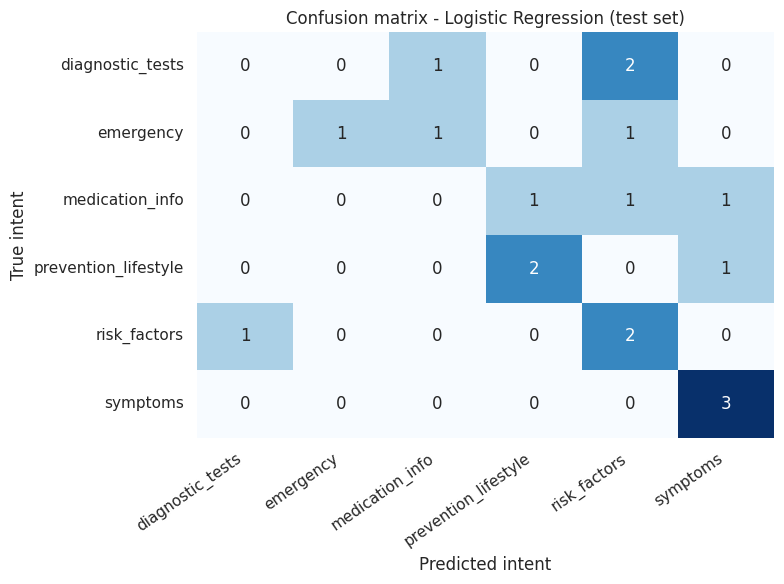

Overall accuracy is 44.44% on 18 unseen queries.
Best F1: symptoms (0.75); weakest F1: diagnostic_tests (0.00).
Misclassified (true -> predicted): [('emergency', 'medication_info'), ('diagnostic_tests', 'risk_factors'), ('medication_info', 'symptoms'), ('risk_factors', 'diagnostic_tests'), ('medication_info', 'risk_factors'), ('diagnostic_tests', 'risk_factors'), ('medication_info', 'prevention_lifestyle'), ('prevention_lifestyle', 'symptoms'), ('diagnostic_tests', 'medication_info'), ('emergency', 'risk_factors')]


In [7]:
y_pred = lr_pipeline.predict(X_test)
labels = sorted(df["intent"].unique())

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("\nClassification report (precision / recall / F1 per intent):\n")
print(classification_report(y_test, y_pred, labels=labels, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=labels)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels, cbar=False)
plt.xlabel("Predicted intent"); plt.ylabel("True intent")
plt.title("Confusion matrix - Logistic Regression (test set)")
plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

# ---- Automatic interpretation ----
rep = classification_report(y_test, y_pred, labels=labels, output_dict=True, zero_division=0)
per_class = {l: rep[l]["f1-score"] for l in labels}
best, worst = max(per_class, key=per_class.get), min(per_class, key=per_class.get)
wrong = [(t, p) for t, p in zip(y_test, y_pred) if t != p]
print(f"Overall accuracy is {accuracy_score(y_test, y_pred):.2%} on {len(y_test)} unseen queries.")
print(f"Best F1: {best} ({per_class[best]:.2f}); weakest F1: {worst} ({per_class[worst]:.2f}).")
print("Misclassified (true -> predicted):", wrong if wrong else "none")

### Interpreting the results
* **Accuracy / macro-F1** summarise overall quality. Because the test set is tiny (18 queries, 3 per intent), a single wrong prediction changes the scores noticeably, so these numbers are indicative rather than definitive.
* **Precision** tells us how often a predicted intent is correct; **recall** tells us how many true queries of an intent were found. A low recall for an intent means its queries are being mistaken for another intent.
* The **confusion matrix** shows *which* intents get mixed up. Intents that share vocabulary (for example `symptoms` and `emergency`, which both mention *heart attack* and *chest pain*, or `medication_info` and `diagnostic_tests`, which both mention *blood pressure*/*cholesterol*) are the most likely to be confused.
* Limitation: the corpus is small and hand-written. A real system would need many more (ideally real, anonymised) queries. This is also why the assistant adds **rules** (Section 8) such as low-confidence handling on top of the model.

## 7. Domain-Specific Knowledge Base
A Python dictionary holds general, education-level heart-health information for **every intent**. Each intent has an `overview` and several finer-grained `topics`; each topic has `keywords` (regular-expression fragments matched against the user's query) so the assistant can return the most relevant passage instead of a generic answer. Information is general and based on widely published guidance (e.g. WHO / major cardiology bodies); it is not personal medical advice.

In [8]:
KNOWLEDGE_BASE = {
    # ------------------------------------------------------------------ SYMPTOMS
    "symptoms": {
        "title": "Heart symptoms",
        "overview": ("Heart problems can cause chest pain, pressure or tightness; shortness of breath; palpitations "
                     "(a racing, pounding or irregular heartbeat); unusual tiredness; dizziness or fainting; and swelling "
                     "of the ankles or feet. Symptoms differ from person to person, and in women, older adults and people "
                     "with diabetes they can be mild or unusual."),
        "topics": {
            "Heart attack": {
                "keywords": [r"heart attack", r"women", r"woman", r"female"],
                "info": ("Typical heart attack symptoms are pressure, squeezing or heaviness in the centre of the chest lasting "
                         "more than a few minutes, pain spreading to the arm(s), shoulder, back, neck or jaw, shortness of breath, "
                         "cold sweat, nausea and light-headedness. Women may have subtler symptoms such as unusual fatigue, nausea, "
                         "jaw or back pain and breathlessness, sometimes without much chest pain. Suspected heart attack is an "
                         "emergency: call 112 immediately.")},
            "Angina / chest pain": {
                "keywords": [r"angina", r"chest", r"walk"],
                "info": ("Angina is chest discomfort (pressure, tightness or heaviness) that happens when the heart muscle gets too "
                         "little oxygen-rich blood. It is often brought on by exertion, stress or cold and eases with rest or "
                         "prescribed medicine. New chest pain, pain that is getting worse or pain that occurs at rest needs prompt "
                         "medical evaluation.")},
            "Palpitations / arrhythmia": {
                "keywords": [r"palpitation", r"rac(e|ing)", r"irregular", r"arrhythmi", r"heartbeat", r"skip", r"flutter", r"pound"],
                "info": ("Palpitations are an awareness of fast, pounding, fluttering or skipped heartbeats. They are often harmless "
                         "(caffeine, stress, fever, anxiety) but can also be caused by an arrhythmia such as atrial fibrillation. "
                         "See a doctor if they are frequent or prolonged, or come with dizziness, fainting, chest pain or breathlessness.")},
            "Heart failure": {
                "keywords": [r"swollen", r"swelling", r"ankle", r"failure", r"fatigue", r"tired", r"weak", r"breath"],
                "info": ("In heart failure the heart does not pump blood as well as the body needs. Common symptoms are breathlessness "
                         "(especially on exertion or when lying flat), persistent tiredness, swelling of the legs, ankles or abdomen, "
                         "rapid weight gain from fluid and a persistent cough. These symptoms should be assessed by a doctor.")},
        },
    },
    # ------------------------------------------------------------------ RISK FACTORS
    "risk_factors": {
        "title": "Heart disease risk factors",
        "overview": ("Non-modifiable risk factors include age, male sex (women's risk rises after menopause), family history and "
                     "South Asian ancestry. Modifiable risk factors include high blood pressure, high LDL cholesterol, smoking or "
                     "tobacco use, diabetes, obesity, physical inactivity, an unhealthy diet, excess alcohol, chronic stress and "
                     "poor sleep. Having several risk factors together multiplies the risk."),
        "topics": {
            "High blood pressure": {
                "keywords": [r"blood pressure", r"hypertension", r"bp\b"],
                "info": ("High blood pressure (hypertension) makes the heart work harder and damages artery walls over time. It raises "
                         "the risk of heart attack, stroke, heart failure and kidney disease. It usually has no symptoms, so regular "
                         "blood pressure checks are important.")},
            "High cholesterol": {
                "keywords": [r"cholesterol", r"ldl", r"plaque", r"arter"],
                "info": ("High LDL ('bad') cholesterol and high triglycerides can build up as fatty plaque in artery walls "
                         "(atherosclerosis), narrowing the arteries and raising the risk of angina and heart attack. Low HDL "
                         "('good') cholesterol also adds to risk.")},
            "Smoking": {
                "keywords": [r"smok", r"tobacco", r"cigarette"],
                "info": ("Tobacco smoke damages blood vessels, reduces oxygen in the blood, raises blood pressure and makes blood "
                         "clots more likely. Smokers have a substantially higher risk of heart disease, and the risk falls markedly "
                         "after quitting. Second-hand smoke is also harmful.")},
            "Diabetes": {
                "keywords": [r"diabet", r"sugar"],
                "info": ("Over time, high blood sugar damages blood vessels and the nerves that control the heart. People with diabetes "
                         "are roughly twice as likely to develop heart disease as people without it, and often at a younger age.")},
            "Age, sex, family history and ancestry": {
                "keywords": [r"family", r"age\b", r"older", r"young", r"men\b", r"women", r"gender", r"genetic", r"indian", r"inherit"],
                "info": ("Risk rises with age. Men tend to develop heart disease earlier, while women's risk rises after menopause. "
                         "Having a close relative with early heart disease (father or brother before 55, mother or sister before 65) "
                         "raises risk. People of South Asian origin, including Indians, tend to develop coronary artery disease "
                         "earlier than many other groups.")},
            "Weight, inactivity, stress and sleep": {
                "keywords": [r"obes", r"weight", r"stress", r"sleep", r"habit", r"alcohol", r"inactiv", r"sedentary"],
                "info": ("Excess weight, especially around the abdomen, raises blood pressure, cholesterol and blood sugar. Physical "
                         "inactivity, a diet high in salt, saturated and trans fats, heavy alcohol use, chronic stress and poor sleep "
                         "all add to the risk of heart disease.")},
        },
    },
    # ------------------------------------------------------------------ PREVENTION
    "prevention_lifestyle": {
        "title": "Prevention and heart-healthy lifestyle",
        "overview": ("Most heart disease is largely preventable. Stay physically active (at least 150 minutes of moderate activity "
                     "a week), eat plenty of vegetables, fruit, whole grains, pulses and nuts, limit salt, sugar, fried food and "
                     "processed meat, avoid tobacco, keep a healthy weight, limit alcohol, manage stress, sleep 7-9 hours and have "
                     "your blood pressure, cholesterol and blood sugar checked regularly."),
        "topics": {
            "Exercise": {
                "keywords": [r"exercise", r"walking", r"walk\b", r"yoga", r"active", r"workout", r"physical"],
                "info": ("Adults should aim for at least 150 minutes of moderate-intensity activity (such as brisk walking, cycling or "
                         "swimming) or 75 minutes of vigorous activity per week, plus muscle-strengthening activity on two days. "
                         "Yoga and walking are good options. If you are inactive, older or already have a heart condition, "
                         "start slowly and check with your doctor first.")},
            "Heart-healthy diet": {
                "keywords": [r"diet", r"food", r"eat", r"nutrition", r"cholesterol", r"fat"],
                "info": ("A heart-healthy diet is rich in vegetables, fruit, whole grains (oats, millets, brown rice), pulses, nuts and "
                         "fish, uses unsaturated oils in small amounts, and limits fried foods, processed meat, sweets, refined "
                         "carbohydrates and trans fats. Eating more fibre and fewer saturated fats helps lower LDL cholesterol.")},
            "Salt reduction": {
                "keywords": [r"salt", r"sodium"],
                "info": ("The WHO recommends less than 5 grams of salt (about one teaspoon) a day. Much of our salt comes from pickles, "
                         "papad, namkeen, packaged snacks, instant noodles and restaurant food. Eating less salt helps lower "
                         "blood pressure.")},
            "Quitting tobacco": {
                "keywords": [r"smok", r"tobacco", r"quit"],
                "info": ("Quitting tobacco is one of the most powerful things you can do for your heart; benefits begin within weeks and "
                         "heart attack risk keeps falling over the following years. Counselling, nicotine replacement and "
                         "prescription support are available - ask your doctor.")},
            "Weight and blood pressure": {
                "keywords": [r"weight", r"lose\b", r"losing", r"blood pressure", r"bp\b", r"obes"],
                "info": ("Losing even 5-10 % of body weight can improve blood pressure, cholesterol and blood sugar. Combine regular "
                         "activity, less salt, a balanced diet, limited alcohol and stress management, and monitor your blood "
                         "pressure regularly.")},
        },
    },
    # ------------------------------------------------------------------ MEDICATION INFO
    "medication_info": {
        "title": "Heart medicines (general information)",
        "overview": ("Common heart medicines include statins (lower LDL cholesterol), blood-pressure medicines (ACE inhibitors, ARBs, "
                     "beta blockers, calcium-channel blockers, diuretics), antiplatelets (aspirin, clopidogrel), anticoagulants "
                     "(warfarin and newer agents) and nitrates (for angina). Medicines are chosen individually: never start, stop "
                     "or change a dose without talking to your doctor."),
        "topics": {
            "Statins": {
                "keywords": [r"statin", r"cholesterol"],
                "info": ("Statins (for example atorvastatin and rosuvastatin) lower LDL cholesterol by blocking an enzyme in the liver, "
                         "and reduce the risk of heart attack and stroke. Muscle aches are the most common side effect; rarely, "
                         "liver enzymes rise. Report severe muscle pain or dark urine to your doctor.")},
            "Beta blockers": {
                "keywords": [r"beta"],
                "info": ("Beta blockers (for example metoprolol, atenolol, bisoprolol and carvedilol) slow the heart rate and lower blood "
                         "pressure, reducing the heart's workload. They are used for angina, after a heart attack, in heart failure "
                         "and for some arrhythmias. Tiredness, cold hands and a slow pulse can occur; do not stop them suddenly.")},
            "ACE inhibitors / ARBs / blood-pressure medicines": {
                "keywords": [r"ace inhibitor", r"arb\b", r"blood pressure", r"hypertension", r"antihypertensive", r"ramipril", r"losartan"],
                "info": ("ACE inhibitors (such as ramipril, enalapril) and ARBs (such as losartan, telmisartan) relax blood vessels, "
                         "lowering blood pressure and protecting the heart and kidneys. ACE inhibitors can cause a dry cough, and "
                         "both groups need kidney function and potassium checks. Most people need several medicines combined "
                         "with lifestyle changes.")},
            "Aspirin and blood thinners": {
                "keywords": [r"aspirin", r"thinner", r"anticoag", r"antiplatelet", r"clopidogrel", r"stent", r"warfarin"],
                "info": ("Antiplatelets (aspirin, clopidogrel) make platelets less sticky and are commonly prescribed after a heart attack "
                         "or stent. Anticoagulants (warfarin, apixaban, rivaroxaban) prevent clots in conditions such as atrial "
                         "fibrillation. Both increase bleeding risk, so take them exactly as prescribed and do not start aspirin on "
                         "your own for prevention.")},
            "Nitrates (nitroglycerin)": {
                "keywords": [r"nitro", r"angina", r"\bgtn"],
                "info": ("Nitroglycerin widens blood vessels and relieves angina. It is usually taken as a tablet or spray under the "
                         "tongue while sitting down. If chest pain is not relieved or gets worse, call 112 - do not wait.")},
            "Never stop medicines on your own": {
                "keywords": [r"stop", r"skip", r"quit taking", r"feel better", r"miss"],
                "info": ("Many heart medicines work silently (for blood pressure and cholesterol), so feeling well is not a reason to stop "
                         "them. Stopping suddenly can be dangerous - for example beta blockers, or antiplatelets after a stent. "
                         "Always discuss any change with your doctor.")},
            "After a heart attack / heart failure": {
                "keywords": [r"after a heart attack", r"heart failure", r"failure"],
                "info": ("After a heart attack, people are commonly prescribed an antiplatelet, a statin, a beta blocker and an ACE "
                         "inhibitor or ARB. For heart failure, treatment often includes ACE inhibitors/ARBs (or ARNI), beta blockers, "
                         "mineralocorticoid antagonists, SGLT2 inhibitors and diuretics for fluid. Your cardiologist decides the "
                         "right combination for you.")},
        },
    },
    # ------------------------------------------------------------------ DIAGNOSTIC TESTS
    "diagnostic_tests": {
        "title": "Heart diagnostic tests",
        "overview": ("Common tests include an ECG, echocardiogram, treadmill stress test, Holter (24-hour) monitoring, blood tests "
                     "(troponin, lipid profile, blood sugar, BNP), chest X-ray, CT coronary angiography or calcium score, coronary "
                     "angiography and cardiac MRI. A doctor chooses tests according to your symptoms and risk."),
        "topics": {
            "ECG": {
                "keywords": [r"ecg", r"ekg", r"electrocardiogram", r"electrical"],
                "info": ("An ECG (electrocardiogram) records the heart's electrical activity using small electrodes on the chest, arms "
                         "and legs. It is quick (a few minutes) and painless, and can show abnormal rhythms, signs of a current or "
                         "past heart attack and strain on the heart.")},
            "Echocardiogram": {
                "keywords": [r"echo"],
                "info": ("An echocardiogram is an ultrasound scan of the heart. It shows the size of the chambers, how well the heart "
                         "pumps (ejection fraction), the heart valves and any fluid around the heart. It is painless and uses no "
                         "radiation.")},
            "Stress test": {
                "keywords": [r"stress test", r"treadmill", r"tmt\b", r"exercise test"],
                "info": ("In a treadmill (stress) test, an ECG and blood pressure are recorded while you walk at increasing speed and "
                         "slope. It checks whether exercise brings on reduced blood flow to the heart or abnormal rhythms. "
                         "Medicine-based or imaging stress tests are used for people who cannot exercise.")},
            "Angiography and CT scan": {
                "keywords": [r"angiogra", r"blockage", r"\bct\b", r"scan", r"arteries"],
                "info": ("Coronary angiography uses a thin catheter (through the wrist or groin) and contrast dye with X-rays to show "
                         "blockages in the heart arteries; a stent can sometimes be placed in the same procedure. CT coronary "
                         "angiography is a less invasive scan that can also show narrowing in the arteries.")},
            "Blood tests": {
                "keywords": [r"troponin", r"blood test", r"lipid", r"profile", r"bnp", r"hba1c"],
                "info": ("Troponin rises when heart muscle is damaged and is key in diagnosing a heart attack. A lipid profile measures "
                         "total, LDL and HDL cholesterol and triglycerides. Blood sugar or HbA1c checks for diabetes, and BNP or "
                         "NT-proBNP helps assess heart failure.")},
            "Holter monitor": {
                "keywords": [r"holter", r"monitor", r"rhythm"],
                "info": ("A Holter monitor is a small portable ECG recorder worn for 24-48 hours (or longer with patch monitors) to "
                         "catch rhythm problems that come and go.")},
            "Blood pressure measurement": {
                "keywords": [r"blood pressure", r"measured", r"hypertension"],
                "info": ("Blood pressure is measured with a cuff and gives two numbers (systolic over diastolic). Normal is around "
                         "120/80 mmHg; hypertension is generally diagnosed when readings are repeatedly 140/90 mmHg or higher, "
                         "often confirmed with home or 24-hour monitoring.")},
            "Diagnosing a heart attack": {
                "keywords": [r"diagnosed", r"diagnose", r"heart attack"],
                "info": ("A heart attack is diagnosed from the symptoms, an ECG and blood troponin levels, often followed by "
                         "echocardiography and coronary angiography to find the blocked artery.")},
        },
    },
    # ------------------------------------------------------------------ EMERGENCY
    "emergency": {
        "title": "Heart emergency guidance",
        "overview": ("In a suspected heart emergency call 112 (India's national emergency number; an ambulance can also be reached "
                     "through 102 or 108 in many states) immediately. Do not drive yourself. Sit or lie down, stay calm and loosen "
                     "tight clothing. If the person is unresponsive and not breathing normally, start CPR and use an AED if one is "
                     "available."),
        "topics": {
            "CPR": {
                "keywords": [r"cpr", r"compress", r"stopped", r"pulse", r"not breathing"],
                "info": ("Call 112 first. For hands-only CPR, place the heel of your hand on the centre of the chest and push hard and "
                         "fast - about 100-120 compressions a minute, roughly 5-6 cm deep - letting the chest rise fully between "
                         "pushes. Continue until the ambulance or an AED arrives, or the person starts to move.")},
            "AED": {
                "keywords": [r"aed\b", r"defibrillat", r"shock"],
                "info": ("An AED (automated external defibrillator) gives spoken instructions: switch it on, attach the pads as shown "
                         "in the pictures, let it analyse the rhythm, and press the shock button only if it advises one. Keep "
                         "doing CPR whenever the AED tells you to.")},
            "Aspirin": {
                "keywords": [r"aspirin"],
                "info": ("During a suspected heart attack, chewing a single regular-strength aspirin may be advised if the person is "
                         "not allergic and has no bleeding problem - but only if the emergency operator or a doctor agrees. "
                         "Never delay calling 112 to find aspirin.")},
            "When to call for help": {
                "keywords": [r"when", r"ambulance", r"number", r"call", r"emergency"],
                "info": ("Call 112 immediately for chest pain, pressure or tightness lasting more than a few minutes or returning, "
                         "especially with sweating, nausea, breathlessness or pain spreading to the arm, jaw or back; for sudden "
                         "weakness or trouble speaking (possible stroke); for fainting; or when someone collapses.")},
            "Fainting or collapse": {
                "keywords": [r"faint", r"collaps", r"unconscious", r"unrespons"],
                "info": ("If someone collapses: check for a response and breathing, call 112, and start CPR if they are not breathing "
                         "normally. If they are breathing, lay them on their side (recovery position), keep them warm and stay "
                         "with them until help arrives.")},
        },
    },
}

assert set(KNOWLEDGE_BASE) == set(df["intent"].unique())
for intent, kb in KNOWLEDGE_BASE.items():
    print(f"{intent:22s} -> {len(kb['topics'])} topics: {', '.join(kb['topics'])}")

symptoms               -> 4 topics: Heart attack, Angina / chest pain, Palpitations / arrhythmia, Heart failure
risk_factors           -> 6 topics: High blood pressure, High cholesterol, Smoking, Diabetes, Age, sex, family history and ancestry, Weight, inactivity, stress and sleep
prevention_lifestyle   -> 5 topics: Exercise, Heart-healthy diet, Salt reduction, Quitting tobacco, Weight and blood pressure
medication_info        -> 7 topics: Statins, Beta blockers, ACE inhibitors / ARBs / blood-pressure medicines, Aspirin and blood thinners, Nitrates (nitroglycerin), Never stop medicines on your own, After a heart attack / heart failure
diagnostic_tests       -> 8 topics: ECG, Echocardiogram, Stress test, Angiography and CT scan, Blood tests, Holter monitor, Blood pressure measurement, Diagnosing a heart attack
emergency              -> 5 topics: CPR, AED, Aspirin, When to call for help, Fainting or collapse


## 8. Rule Engine
The rule engine sits around the classifier and decides **when not to trust it** (or when to bypass it). Rules are checked in this order:

| ID | Rule | Trigger | Action |
|----|------|---------|--------|
| R1 | Empty input | blank query | ask the user to type a question |
| R2 | Goodbye / thanks | short message such as "bye", "thanks" | polite goodbye |
| R3 | Greeting | short message such as "hello", "namaste" | greet and list capabilities |
| R4 | **Emergency escalation** | keywords/patterns such as *chest pain radiating*, *can't breathe*, *unconscious*, *heart attack now* | advise calling **112** immediately and **skip classification** |
| R5 | **Unsupported query** | no heart-health vocabulary in the query | polite refusal and list of supported topics |
| R6 | **Low-confidence handling** | max predicted probability < threshold | ask the user to rephrase |
| R7 | Symptom severity advisory | `symptoms` intent + words such as *severe*, *sudden*, *worsening* | add advice to see a doctor promptly |
| R8 | Medication disclaimer | `medication_info` intent | append a "do not change medicines without your doctor" note |
| R9 | General disclaimer | every normal answer | append the educational-purposes disclaimer |

This cell defines the rule patterns and helper functions; Section 9 combines them with the classifier.

In [9]:
CONFIDENCE_THRESHOLD = 0.30     # R6: below this the assistant asks the user to rephrase

# ---- R4: emergency patterns (checked on the raw text, before any classification) ----
EMERGENCY_PATTERNS = [
    r"chest (pain|pressure|tightness|discomfort).{0,50}(radiat|spread|shoot|left arm|jaw|sweat)",
    r"(radiat|spread|shoot|left arm|jaw|sweat).{0,50}chest (pain|pressure|tightness)",
    r"(severe|crushing|intense|excruciating|sudden|unbearable) (chest )?(pain|pressure|tightness)( in| on)?( my| the)? ?chest",
    r"(severe|crushing|intense|excruciating|sudden|unbearable) chest (pain|pressure|tightness)",
    r"(can ?not|can'?t|unable to|cant) (breathe|catch my breath)",
    r"(crushing|crushed|squeezing|heavy) (feeling )?(in )?(my )?chest",
    r"chest (feels|is) (crushed|crushing|squeezed|tight|heavy)",
    r"(i am|i'm|im|someone is|he is|she is|he's|she's|my \w+ is) (having|getting) (a )?(heart attack|cardiac arrest)",
    r"(heart attack|cardiac arrest) (right )?now",
    r"\b(unconscious|unresponsive|passed out|not breathing|stopped breathing|no pulse|collapsed)\b",
]

# ---- R5: heart-health vocabulary (queries without any of these are unsupported) ----
HEART_TERMS = re.compile(
    r"\b(heart\w*|cardi\w*|chest|blood pressure|bp|hypertens\w*|cholesterol|ldl|hdl|triglyceride\w*|lipid\w*|"
    r"ecg|ekg|electrocardiogram|echo\w*|angina|arrhythmi\w*|palpitation\w*|stent\w*|bypass|angioplasty|angiogra\w*|"
    r"statin\w*|arter\w*|coronary|stroke|pulse|aspirin|beta[- ]?blocker\w*|ace inhibitor\w*|nitroglycerin|"
    r"blood thinner\w*|anticoagul\w*|antiplatelet\w*|troponin|treadmill|stress test|holter|defibrillat\w*|aed|cpr|"
    r"pacemaker|atheroscleros\w*|plaque|breath\w*|cvd)\b")

GREETING_RE = re.compile(r"^\s*(hi+|hello+|hey+|namaste|good (morning|afternoon|evening)|greetings)\b[\w\s!.,?]{0,25}$")
GOODBYE_RE  = re.compile(r"\b(bye|goodbye|see you|thanks|thank you|thankyou|exit|quit)\b")
SEVERITY_RE = re.compile(r"\b(severe|sudden|worsening|getting worse|unbearable|faint\w*|persistent|increasing)\b")

SUPPORTED_TOPICS = ("symptoms, risk factors, prevention and healthy lifestyle, heart medicines, "
                    "diagnostic tests and heart emergencies")

def normalise(text):
    return str(text).lower().replace("’", "'").strip()

def is_emergency(text):
    t = normalise(text)
    return any(re.search(p, t) for p in EMERGENCY_PATTERNS)

def is_heart_related(text):
    return bool(HEART_TERMS.search(normalise(text)))

def is_greeting(text):
    t = normalise(text)
    return bool(GREETING_RE.match(t)) and not is_heart_related(t)

def is_goodbye(text):
    t = normalise(text)
    return len(t.split()) <= 6 and bool(GOODBYE_RE.search(t)) and not is_heart_related(t)

def retrieve_knowledge(intent, query):
    """Pick the best matching topic for the query inside the intent's knowledge base."""
    kb, q = KNOWLEDGE_BASE[intent], normalise(query)
    best, best_score = None, 0
    for name, topic in kb["topics"].items():
        score = sum(1 for kw in topic["keywords"] if re.search(r"\b" + kw, q))
        if score > best_score:
            best, best_score = name, score
    if best:
        return f"{kb['title']} - {best}: {kb['topics'][best]['info']}", best
    others = ", ".join(kb["topics"])
    return f"{kb['title']}: {kb['overview']} (You can ask more specifically about: {others}.)", "overview"

RULES = pd.DataFrame([
    ("R1", "empty_input",            "blank query"),
    ("R2", "goodbye_handler",        "short bye / thanks message"),
    ("R3", "greeting_handler",       "short hello / namaste message"),
    ("R4", "emergency_escalation",   "emergency keyword patterns -> call 112, skip classifier"),
    ("R5", "unsupported_query",      "no heart-health vocabulary -> polite refusal"),
    ("R6", "low_confidence",         f"max probability < {CONFIDENCE_THRESHOLD} -> ask to rephrase"),
    ("R7", "symptom_severity_advice","symptoms intent + severity words -> see a doctor promptly"),
    ("R8", "medication_disclaimer",  "medication_info intent -> doctor-consultation note"),
    ("R9", "general_disclaimer",     "every normal answer -> educational-use disclaimer"),
], columns=["id", "rule", "trigger -> action"])
display(RULES)

# quick sanity checks of the rule helpers
print("Emergency?  ", is_emergency("I have severe chest pain spreading to my left arm"),
      "|", is_emergency("What are the symptoms of chest pain?"))
print("Heart-related?", is_heart_related("What is an ECG?"), "|", is_heart_related("How do I treat a broken arm?"))

,id,rule,trigger -> action
0,R1,empty_input,blank query
1,R2,goodbye_handler,short bye / thanks message
2,R3,greeting_handler,short hello / namaste message
3,R4,emergency_escalation,"emergency keyword patterns -> call 112, skip classifier"
4,R5,unsupported_query,no heart-health vocabulary -> polite refusal
5,R6,low_confidence,max probability < 0.3 -> ask to rephrase
6,R7,symptom_severity_advice,symptoms intent + severity words -> see a doctor promptly
7,R8,medication_disclaimer,medication_info intent -> doctor-consultation note
8,R9,general_disclaimer,every normal answer -> educational-use disclaimer


Emergency?   True | False
Heart-related? True | False


## 9. Integration – the `assistant(query)` function
`assistant(query)` ties everything together in one call:

1. **Rules R1-R3** handle empty input, goodbyes and greetings.
2. **R4 – emergency escalation** inspects the raw query *before* classification and, if triggered, immediately returns the 112 advice.
3. **R5 – unsupported-query check**.
4. **NLP preprocessing** (lowercase → tokenize → stopwords → lemmatize) and **TF-IDF + Logistic Regression** intent classification with a confidence score.
5. **R6 – low-confidence handling**.
6. **Knowledge retrieval** for the predicted intent, then **R7 / R8 / R9** add severity advice, the medication note and the disclaimer.

The function returns a structured dictionary: `query`, `intent`, `confidence`, `rule_triggered`, `taxonomy_path`, `response`. For the deployed assistant, the classifier is **re-trained on the whole corpus** (the earlier train/test split was only used to evaluate the model honestly).

In [10]:
# Final deployed model: same pipeline, fitted on ALL labelled queries
final_model = make_pipeline(LogisticRegression(C=10, max_iter=1000, random_state=SEED))
final_model.fit(df["clean"], df["intent"])
print("Deployed model classes:", list(final_model.classes_))

EMERGENCY_RESPONSE = (
    "EMERGENCY - THIS MAY BE A LIFE-THREATENING SITUATION.\n"
    "1) CALL 112 NOW (India's national emergency number; ambulance 102/108 in many states). Do not wait and do not drive yourself.\n"
    "2) Stay calm, sit or lie down, loosen tight clothing and avoid any exertion.\n"
    "3) If a doctor or the emergency operator advises it and there is no aspirin allergy or bleeding problem, chewing one regular aspirin may be recommended.\n"
    "4) If the person is unresponsive and not breathing normally, start hands-only CPR (hard and fast in the centre of the chest) and use an AED if available.")

def _result(query, intent, confidence, rule, response, add_disclaimer=True):
    if add_disclaimer:
        response = response + "\n\nNote: " + DISCLAIMER
    path = " > ".join(INTENT_TO_TAXONOMY[intent]) if intent in INTENT_TO_TAXONOMY else "-"
    return {"query": query, "intent": intent, "confidence": confidence,
            "rule_triggered": rule, "taxonomy_path": path, "response": response}

def assistant(query):
    """Full pipeline: rules -> preprocessing -> intent classification -> reasoning -> knowledge retrieval."""
    raw = "" if query is None else str(query).strip()

    # R1 - empty input
    if not raw:
        return _result(raw, "none", None, "R1 empty_input",
                       "Please type a question about heart health.", add_disclaimer=False)
    # R2 - goodbye / thanks
    if is_goodbye(raw):
        return _result(raw, "goodbye", None, "R2 goodbye_handler",
                       "You're welcome! Take care of your heart. Goodbye!")
    # R3 - greeting
    if is_greeting(raw):
        return _result(raw, "greeting", None, "R3 greeting_handler",
                       "Hello! I am a Heart Health Information Assistant. I can answer general questions about "
                       + SUPPORTED_TOPICS + ".")
    # R4 - emergency escalation (bypasses the classifier completely)
    if is_emergency(raw):
        return _result(raw, "emergency", None, "R4 emergency_escalation", EMERGENCY_RESPONSE)
    # R5 - unsupported (non-heart / non-health) queries
    if not is_heart_related(raw):
        return _result(raw, "unsupported", None, "R5 unsupported_query",
                       "I'm sorry, I can only help with heart-health questions (" + SUPPORTED_TOPICS + "). "
                       "For other health concerns, please consult a qualified doctor.")

    # --- NLP preprocessing + intent classification ---
    clean = preprocess(raw)
    probs = final_model.predict_proba([clean])[0]
    best_idx = int(np.argmax(probs))
    intent, confidence = final_model.classes_[best_idx], float(probs[best_idx])

    # R6 - low confidence
    if confidence < CONFIDENCE_THRESHOLD or not clean:
        return _result(raw, intent, round(confidence, 3), "R6 low_confidence",
                       f"I'm not sure I understood your question (confidence {confidence:.0%}). Could you please "
                       "rephrase it or add more detail? For example: 'What are the symptoms of a heart attack?' or "
                       "'Which foods are good for my heart?'")

    # --- Knowledge retrieval ---
    answer, topic = retrieve_knowledge(intent, raw)
    rules_fired = []

    # R7 - severity advisory for symptom questions
    if intent == "symptoms" and SEVERITY_RE.search(normalise(raw)):
        answer += ("\n\nBecause you mention severe, sudden or worsening symptoms, please see a doctor promptly. "
                   "If there is chest pain, breathlessness or fainting, call 112.")
        rules_fired.append("R7 symptom_severity_advice")
    # R8 - medication disclaimer
    if intent == "medication_info":
        answer += ("\n\nMedication note: this is general information only. Never start, stop or change a medicine or "
                   "its dose without consulting your doctor or pharmacist.")
        rules_fired.append("R8 medication_disclaimer")

    rule = " + ".join(rules_fired) if rules_fired else "None (classifier + knowledge base)"
    return _result(raw, intent, round(confidence, 3), rule, answer)

# ---- Quick demonstration of the structured output ----
demo = assistant("What do statins do?")
for k, v in demo.items():
    print(f"{k:15s}: {v}")

Deployed model classes: ['diagnostic_tests', 'emergency', 'medication_info', 'prevention_lifestyle', 'risk_factors', 'symptoms']
query          : What do statins do?
intent         : medication_info
confidence     : 0.843
rule_triggered : R8 medication_disclaimer
taxonomy_path  : Diagnosis and Treatment > Medications
response       : Heart medicines (general information) - Statins: Statins (for example atorvastatin and rosuvastatin) lower LDL cholesterol by blocking an enzyme in the liver, and reduce the risk of heart attack and stroke. Muscle aches are the most common side effect; rarely, liver enzymes rise. Report severe muscle pain or dark urine to your doctor.

Medication note: this is general information only. Never start, stop or change a medicine or its dose without consulting your doctor or pharmacist.

Note: This information is for educational purposes only and is not a substitute for professional medical advice, diagnosis or treatment.


## Testing Section
The assistant is tested automatically with:
1. **One query for each defined intent** (6 queries, all new – not in the training corpus)
2. **Differently worded (paraphrased) queries** for several intents
3. **Unsupported queries** (a healthcare query outside heart health, and a non-health query)
4. **Low-confidence / vague queries**
5. **Emergency queries**
6. A greeting and a goodbye (extra rule checks)

Results are shown in a table with the columns *query, predicted intent, confidence, rule triggered, response*. For rules that bypass the classifier (emergency, unsupported, greeting, goodbye) there is no classifier confidence, so it is shown as `n/a (rule-based)`.

In [13]:
test_cases = [
    # (test type, query)
    ("1. intent: symptoms",              "What are the signs that something is wrong with my heart?"),
    ("1. intent: risk_factors",          "Which conditions make a person more prone to coronary artery disease?"),
    ("1. intent: prevention_lifestyle",  "What can I eat and do every day to protect my heart?"),
    ("1. intent: medication_info",       "What is the purpose of taking statins daily?"),
    ("1. intent: diagnostic_tests",      "Which test records the electrical activity of the heart?"),
    ("1. intent: emergency",             "A person suddenly collapsed and has no pulse, what should I do?"),
    ("2. paraphrase: symptoms",          "Why does my heartbeat feel fluttery and uneven?"),
    ("2. paraphrase: risk_factors",      "Is cigarette smoking harmful for my cardiovascular health?"),
    ("2. paraphrase: prevention",        "How can I lower my blood pressure through exercise and diet?"),
    ("2. paraphrase: medication_info",   "Do I have to keep taking my blood pressure tablets for life?"),
    ("2. paraphrase: diagnostic_tests",  "Which blood test shows that the heart muscle is damaged?"),
    ("3. unsupported (healthcare)",      "How do I treat a broken arm?"),
    ("3. unsupported (healthcare)",      "What is the best medicine for a skin allergy?"),
    ("3. unsupported (non-health)",      "Who won the cricket match yesterday?"),
    ("4. low confidence / vague",        "heart"),
    ("4. low confidence / vague",        "I want to know about the heart"),
    ("4. vague (no domain words)",       "tell me something"),
    ("5. emergency",                     "I have severe chest pain spreading to my left arm and I'm sweating"),
    ("5. emergency",                     "I can't breathe and my chest feels crushed"),
    ("6. greeting",                      "Hello"),
    ("6. goodbye",                       "Thanks, bye"),
]

records = []
for label, q in test_cases:
    r = assistant(q)
    conf = "n/a (rule-based)" if r["confidence"] is None else f"{r['confidence']:.2f}"
    records.append({"test type": label, "query": q, "predicted intent": r["intent"],
                    "confidence": conf, "rule triggered": r["rule_triggered"], "response": r["response"]})

results_df = pd.DataFrame(records)
results_df.index = range(1, len(results_df) + 1)      # unique index (required by the pandas Styler)
results_df.index.name = "#"
styled = results_df.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap",
                                            "vertical-align": "top"})
display(styled)

,test type,query,predicted intent,confidence,rule triggered,response
#,,,,,,
1,1. intent: symptoms,What are the signs that something is wrong with my heart?,symptoms,0.70,None (classifier + knowledge base),"Heart symptoms: Heart problems can cause chest pain, pressure or tightness; shortness of breath; palpitations (a racing, pounding or irregular heartbeat); unusual tiredness; dizziness or fainting; and swelling of the ankles or feet. Symptoms differ from person to person, and in women, older adults and people with diabetes they can be mild or unusual. (You can ask more specifically about: Heart attack, Angina / chest pain, Palpitations / arrhythmia, Heart failure.) Note: This information is for educational purposes only and is not a substitute for professional medical advice, diagnosis or treatment."
2,1. intent: risk_factors,Which conditions make a person more prone to coronary artery disease?,risk_factors,0.53,None (classifier + knowledge base),"Heart disease risk factors - High cholesterol: High LDL ('bad') cholesterol and high triglycerides can build up as fatty plaque in artery walls (atherosclerosis), narrowing the arteries and raising the risk of angina and heart attack. Low HDL ('good') cholesterol also adds to risk. Note: This information is for educational purposes only and is not a substitute for professional medical advice, diagnosis or treatment."
3,1. intent: prevention_lifestyle,What can I eat and do every day to protect my heart?,prevention_lifestyle,0.55,None (classifier + knowledge base),"Prevention and heart-healthy lifestyle - Heart-healthy diet: A heart-healthy diet is rich in vegetables, fruit, whole grains (oats, millets, brown rice), pulses, nuts and fish, uses unsaturated oils in small amounts, and limits fried foods, processed meat, sweets, refined carbohydrates and trans fats. Eating more fibre and fewer saturated fats helps lower LDL cholesterol. Note: This information is for educational purposes only and is not a substitute for professional medical advice, diagnosis or treatment."
4,1. intent: medication_info,What is the purpose of taking statins daily?,medication_info,0.85,R8 medication_disclaimer,"Heart medicines (general information) - Statins: Statins (for example atorvastatin and rosuvastatin) lower LDL cholesterol by blocking an enzyme in the liver, and reduce the risk of heart attack and stroke. Muscle aches are the most common side effect; rarely, liver enzymes rise. Report severe muscle pain or dark urine to your doctor. Medication note: this is general information only. Never start, stop or change a medicine or its dose without consulting your doctor or pharmacist. Note: This information is for educational purposes only and is not a substitute for professional medical advice, diagnosis or treatment."
5,1. intent: diagnostic_tests,Which test records the electrical activity of the heart?,diagnostic_tests,0.72,None (classifier + knowledge base),"Heart diagnostic tests - ECG: An ECG (electrocardiogram) records the heart's electrical activity using small electrodes on the chest, arms and legs. It is quick (a few minutes) and painless, and can show abnormal rhythms, signs of a current or past heart attack and strain on the heart. Note: This information is for educational purposes only and is not a substitute for professional medical advice, diagnosis or treatment."
6,1. intent: emergency,"A person suddenly collapsed and has no pulse, what should I do?",emergency,n/a (rule-based),R4 emergency_escalation,"EMERGENCY - THIS MAY BE A LIFE-THREATENING SITUATION. 1) CALL 112 NOW (India's national emergency number; ambulance 102/108 in many states). Do not wait and do not drive yourself. 2) Stay calm, sit or lie down, loosen tight clothing and avoid any exertion. 3) If a doctor or the emergency operator advises it and there is no aspirin allergy or bleeding problem, chewing one regular aspirin may be recommended. 4) If the person is unresponsive and not breathing normally, start hands-only CPR (hard 

In [14]:
# Printed outputs for a few key cases (so the behaviour is visible without scrolling the table)
for q in ["What do statins do?", "heart", "How do I treat a broken arm?",
          "I have severe chest pain spreading to my left arm and I'm sweating"]:
    r = assistant(q)
    print("=" * 90)
    print("QUERY      :", r["query"])
    print("INTENT     :", r["intent"], "| CONFIDENCE:", r["confidence"], "| RULE:", r["rule_triggered"])
    print("TAXONOMY   :", r["taxonomy_path"])
    print("RESPONSE   :", r["response"])

# Summary of the rules that fired during the test run
print("\n" + "=" * 90)
print("Rules triggered during testing:")
display(results_df["rule triggered"].value_counts().to_frame("times"))

QUERY      : What do statins do?
INTENT     : medication_info | CONFIDENCE: 0.843 | RULE: R8 medication_disclaimer
TAXONOMY   : Diagnosis and Treatment > Medications
RESPONSE   : Heart medicines (general information) - Statins: Statins (for example atorvastatin and rosuvastatin) lower LDL cholesterol by blocking an enzyme in the liver, and reduce the risk of heart attack and stroke. Muscle aches are the most common side effect; rarely, liver enzymes rise. Report severe muscle pain or dark urine to your doctor.

Medication note: this is general information only. Never start, stop or change a medicine or its dose without consulting your doctor or pharmacist.

Note: This information is for educational purposes only and is not a substitute for professional medical advice, diagnosis or treatment.
QUERY      : heart
INTENT     : risk_factors | CONFIDENCE: 0.271 | RULE: R6 low_confidence
TAXONOMY   : Risk Factors > Modifiable
RESPONSE   : I'm not sure I understood your question (confidence 27

,times
rule triggered,
None (classifier + knowledge base),8
R5 unsupported_query,4
R4 emergency_escalation,3
R8 medication_disclaimer,2
R6 low_confidence,2
R3 greeting_handler,1
R2 goodbye_handler,1


## 10. Deployment in Google Colab – Interactive Interface
Three ways to use the assistant interactively:

* **10A. ipywidgets version** (optional) – a text box and *Ask* button. `ipywidgets` is pre-installed in Colab.
* **10B. Gradio version** (optional) – a small web chat UI. Set `RUN_GRADIO = True` to install Gradio and launch it.
* **10C. `input()` loop** – the main interface. It accepts as many queries as you like and stops when you type **`exit`**. (This is the last cell; it waits for your input.)

In [15]:
# ---- 10A. Optional ipywidgets interface ----
try:
    import ipywidgets as widgets

    box = widgets.Text(placeholder="Ask a heart-health question...", layout=widgets.Layout(width="70%"))
    button = widgets.Button(description="Ask", button_style="primary")
    out = widgets.Output()

    def on_ask(_):
        with out:
            out.clear_output()
            r = assistant(box.value)
            conf = "n/a" if r["confidence"] is None else f"{r['confidence']:.2f}"
            print(f"Intent: {r['intent']} | Confidence: {conf} | Rule: {r['rule_triggered']}\n")
            print(r["response"])

    button.on_click(on_ask)
    print("Educational use only. In an emergency, call 112.")
    display(widgets.HBox([box, button]), out)
except Exception as e:
    print("ipywidgets interface not available in this environment:", e)

Educational use only. In an emergency, call 112.


Output()

In [18]:
# ---- 10B. Optional Gradio interface (installs gradio only if you switch it on) ----
RUN_GRADIO = True      # <- change to True to launch the Gradio web UI

if RUN_GRADIO:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gradio"])
    import gradio as gr

    def gradio_chat(message):
        r = assistant(message)
        conf = "n/a" if r["confidence"] is None else f"{r['confidence']:.2f}"
        return r["intent"], conf, r["rule_triggered"], r["response"]

    demo_ui = gr.Interface(
        fn=gradio_chat,
        inputs=gr.Textbox(label="Your heart-health question", lines=2),
        outputs=[gr.Textbox(label="Predicted intent"), gr.Textbox(label="Confidence"),
                 gr.Textbox(label="Rule triggered"), gr.Textbox(label="Response", lines=10)],
        title="Heart Health Information Assistant",
        description="Educational purposes only - not a substitute for professional medical advice. "
                    "In an emergency call 112.")
    demo_ui.launch()
else:
    print("Gradio version skipped (set RUN_GRADIO = True to enable).")

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f01a7f7609de9871fc.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ---- 10C. Interactive input() loop - type "exit" to stop ----
RUN_CHAT_LOOP = True     # set to False if you want "Run all" to finish without waiting for input

def chat_loop():
    print("=" * 70)
    print("HEART HEALTH INFORMATION ASSISTANT")
    print(DISCLAIMER)
    print("In a medical emergency call 112 immediately.")
    print('Ask me anything about heart health. Type "exit" to quit.')
    print("=" * 70)
    while True:
        try:
            query = input("\nYou: ")
        except (EOFError, KeyboardInterrupt):
            print("\nSession ended.")
            break
        if query.strip().lower() in {"exit", "quit"}:
            print("Assistant: Goodbye! Take care of your heart.")
            break
        r = assistant(query)
        conf = "n/a" if r["confidence"] is None else f"{r['confidence']:.2f}"
        print(f"\n[intent: {r['intent']} | confidence: {conf} | rule: {r['rule_triggered']}]")
        print("Assistant:", r["response"])

if RUN_CHAT_LOOP:
    chat_loop()

HEART HEALTH INFORMATION ASSISTANT
This information is for educational purposes only and is not a substitute for professional medical advice, diagnosis or treatment.
In a medical emergency call 112 immediately.
Ask me anything about heart health. Type "exit" to quit.

You: What are the warning signs of a heart attack in women?

[intent: symptoms | confidence: 0.88 | rule: None (classifier + knowledge base)]
Assistant: Heart symptoms - Heart attack: Typical heart attack symptoms are pressure, squeezing or heaviness in the centre of the chest lasting more than a few minutes, pain spreading to the arm(s), shoulder, back, neck or jaw, shortness of breath, cold sweat, nausea and light-headedness. Women may have subtler symptoms such as unusual fatigue, nausea, jaw or back pain and breathlessness, sometimes without much chest pain. Suspected heart attack is an emergency: call 112 immediately.

Note: This information is for educational purposes only and is not a substitute for professional me

---
### Summary
The notebook implements all ten required components: a labelled corpus (72 queries, 6 intents), a hierarchical taxonomy, a domain knowledge graph (20 concepts, 24 relations), NLTK preprocessing, TF-IDF with Logistic Regression (compared with Naive Bayes and SVM), evaluation with a confusion matrix, a domain knowledge base, a 9-rule engine, an integrated `assistant()` function and interactive deployment.

**Limitations:** the corpus is small and hand-written, retrieval is keyword-based, and the knowledge base gives only general information. The assistant must never be used for diagnosis or treatment decisions.

> **Disclaimer:** For educational purposes only. Not a substitute for professional medical advice. In an emergency call **112** (India).